# iAmTime forecasting demo on energy data

[iAmTime](https://arxiv.org/abs/2603.22586) is a time-series foundation model that accepts **in-context examples**: completed (history → future) demonstrations passed together with the series to forecast. This notebook is the energy-domain counterpart of `iamtime_walmart_forecasting_demo.ipynb`. It uses public energy datasets from [fev-bench](https://huggingface.co/spaces/autogluon/fev-bench) (`autogluon/fev_datasets`) and keeps the same three-part format per section:

| Part | What you get |
|---|---|
| **Input card** | the exact array / dict shape passed to `predict_quantiles` |
| **Hero figure** | history → forecast fan (10–90 %) + median, observed future overlaid, and one **dashed reference line** = "what you would get without the feature" |
| **Honesty table** | the same comparison on many series or forecast origins: mean / median MASE, win rate, paired bootstrap CI |

| § | Task | fev-bench dataset | Horizon | Reference line | Why this dataset |
|---|---|---|---|---|---|
| 1 | Univariate forecasting | `ercot_1H`: hourly load of the 8 ERCOT (Texas) weather zones | 168 h | seasonal naive (same hour last week) | long, clean load series with daily and weekly cycles |
| 2 | Multivariate forecasting | `ETT_1H`: electricity transformer, 6 load channels + oil temperature | 168 h | univariate forecast of the same channel | fev-bench treats all 7 channels as one multivariate target |
| 3 | Exogenous variables and what-if scenarios | `epf_*`: day-ahead electricity prices of 5 markets (BE, DE, FR, NP, PJM) | 24 h | forecast without covariates | the covariates are **day-ahead load and renewable-generation forecasts**, genuinely known before the price is set |
| 4 | Forecasting with examples (ICL) | `entsoe_1H` aggregated to daily national load of 6 countries (AT, BE, DE, HU, LU, NL) | 28 days | zero-shot from the same 56-day context | strong yearly effects (holidays, heating season) that a short context cannot see but past years can demonstrate |

Other fev-bench energy datasets that fit the same workflows: `entsoe_1H` with its weather covariates (temperature, solar radiation) for Section 3, `proenfo_gfc12/14/17` (utility load with air temperature) for Section 3, `solar_with_weather_*` (PV output with known and past-only weather covariates) for Section 3, `kdd_cup_2022_*` (134 wind turbines with past-only SCADA covariates), and `proenfo_bull` (41 buildings of 5 usage types). On `proenfo_bull`, examples from same-usage buildings did not improve on zero-shot in our tests, even for 14-day cold starts, because two weeks of history already contain the weekly cycle that drives building load.

Checkpoint: [`anishsaha/iAmTime-base-forecast`](https://huggingface.co/anishsaha/iAmTime-base-forecast). Figures are saved to `docs/figures/` (relative to the notebook).

## Setup

Install the package with the notebook and training extras from the repository root (the `training` extra provides `datasets` and `pandas`):

```bash
pip install -e ".[notebook,training]"
```

The first run downloads the checkpoint and the datasets from the Hugging Face Hub and caches them locally.

In [1]:
from datetime import timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from matplotlib.ticker import FuncFormatter

from iAmTime.pipeline import iAmTimePipeline

plt.style.use("seaborn-v0_8-whitegrid")
np.set_printoptions(precision=3, suppress=True)

In [2]:
if torch.cuda.is_available():
    DEVICE = "cuda"
    TORCH_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float32
else:
    DEVICE = "cpu"
    TORCH_DTYPE = torch.float32

MODEL_ID = "anishsaha/iAmTime-base-forecast"

print(f"Device: {DEVICE}")
print(f"Dtype: {TORCH_DTYPE}")
print(f"Model: {MODEL_ID}")

Device: cpu
Dtype: torch.float32
Model: anishsaha/iAmTime-base-forecast


In [3]:
pipeline = iAmTimePipeline.from_pretrained(
    MODEL_ID,
    device_map=DEVICE,
    dtype=TORCH_DTYPE,
)
pipeline.model.eval()
print("Pipeline loaded successfully.")

Pipeline loaded successfully.


### Helpers: data, forecasts, evaluation, plots

Every dataset is loaded with the same helper: one row per item, with the target and covariates as equal-length arrays. Rare gaps (ERCOT has 18 missing hours per zone) are filled by linear interpolation.

Forecasts are scored with **MASE**: the mean absolute error of the median forecast divided by the in-sample mean absolute error of a seasonal naive forecast on the context (season 24 for hourly data, 7 for daily data, as in fev-bench). Lower is better. Each section ends with a **scorecard**: mean and median MASE, the win rate against a reference variant, and a paired bootstrap 95 % CI on the mean difference.

In [4]:
DATASET_PATH = "autogluon/fev_datasets"
QUANTILE_LEVELS = [0.1, 0.5, 0.9]
COLORS = {"history": "#3f4652", "truth": "#23836b", "forecast": "#8f5fa2", "reference": "#d08c2e"}
DAY, WEEK = 24, 168  # Hours.

FIG_DIR = Path("docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"energy_{name}.png", dpi=130, bbox_inches="tight")

def load_config(config):
    return load_dataset(DATASET_PATH, config, split="train").to_pandas()

def column_matrix(frame, column):
    matrix = np.stack([np.asarray(values, dtype=np.float64) for values in frame[column]])
    return pd.DataFrame(matrix.T).interpolate(limit_direction="both").to_numpy().T.astype(np.float32)

def predict(input_batch, horizon):
    quantiles, _ = pipeline.predict_quantiles(input_batch, prediction_length=horizon, quantile_levels=QUANTILE_LEVELS)
    return quantiles.detach().cpu().numpy() if isinstance(quantiles, torch.Tensor) else quantiles

def mase(history, truth, forecast, season):
    scale = np.mean(np.abs(history[season:] - history[:-season]))
    return float(np.mean(np.abs(truth - forecast)) / max(scale, 1e-6))

def seasonal_naive(history, horizon, season):
    return np.resize(history[-season:], horizon)

def scorecard(scores, reference, n_boot=2000, seed=0):
    # scores: DataFrame, one column per variant, one row per forecast, values = MASE.
    rng = np.random.default_rng(seed)
    n = len(scores)
    idx = rng.integers(0, n, size=(n_boot, n))
    ref = scores[reference].to_numpy()
    rows = []
    for name in scores.columns:
        s = scores[name].to_numpy()
        diff = s - ref
        mean_ci = np.percentile(s[idx].mean(axis=1), [2.5, 97.5])
        diff_ci = np.percentile(diff[idx].mean(axis=1), [2.5, 97.5])
        rows.append({
            "mean MASE": s.mean(), "mean 95% CI": f"[{mean_ci[0]:.3f}, {mean_ci[1]:.3f}]",
            "median MASE": np.median(s),
            "win rate vs ref": np.nan if name == reference else (s < ref).mean(),
            "Δ mean vs ref": diff.mean(), "Δ 95% CI": f"[{diff_ci[0]:.3f}, {diff_ci[1]:.3f}]",
        })
    table = pd.DataFrame(rows, index=scores.columns)
    table.index.name = f"reference: {reference}"
    return table.round(3)

def plot_ladder(scores, reference, title, name=None, n_boot=2000):
    # Horizontal bars of mean MASE with bootstrap CIs; the reference bar is grey.
    rng = np.random.default_rng(0)
    idx = rng.integers(0, len(scores), size=(n_boot, len(scores)))
    means = scores.mean()
    cis = np.stack([np.percentile(scores[c].to_numpy()[idx].mean(axis=1), [2.5, 97.5]) for c in scores.columns])
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(scores.columns) + 1.2))
    y = np.arange(len(scores.columns))[::-1]
    colors = ["#9a9a9a" if c == reference else COLORS["forecast"] for c in scores.columns]
    ax.barh(y, means, color=colors, height=0.6)
    ax.errorbar(means, y, xerr=[means - cis[:, 0], cis[:, 1] - means], fmt="none", ecolor="#333333", capsize=3, lw=1)
    ax.set_yticks(y, scores.columns)
    ax.set_xlabel(f"mean MASE over {len(scores)} forecasts (bootstrap 95% CI)")
    ax.set_title(title)
    ax.axvline(means[reference], color="#9a9a9a", lw=0.8, ls="--")
    plt.tight_layout()
    if name:
        savefig(fig, name)
    plt.show()

def plot_forecast(ax, history_x, history, future_x, truth, quantiles, title, reference=None, reference_label=None, ylabel=None):
    ax.plot(history_x, history, color=COLORS["history"], lw=1.1, label="History")
    ax.plot(future_x, truth, color=COLORS["truth"], lw=1.3, label="Observed future")
    ax.fill_between(future_x, quantiles[:, 0], quantiles[:, 2], color=COLORS["forecast"], alpha=0.20, label="10-90% interval")
    ax.plot(future_x, quantiles[:, 1], color=COLORS["forecast"], lw=1.6, label="Median forecast")
    if reference is not None:
        ax.plot(future_x, reference, color=COLORS["reference"], lw=1.2, ls="--", label=reference_label)
    ax.axvline(future_x[0], color="#999999", lw=0.8, ls="--")
    ax.set_title(title)
    if ylabel:
        ax.set_ylabel(ylabel)

## 1. Univariate forecasting: ERCOT zonal load

**Data.** `ercot_1H`: hourly electricity load (MW) of the 8 ERCOT weather zones in Texas, 2004–2021.

**Input card.** A two-dimensional array with shape `(batch, context)`:

```python
uni_input = ercot_load[zone_rows, origin - HOURLY_CONTEXT:origin]      # (3, 1344): 8 weeks of hourly load
quantiles, _ = pipeline.predict_quantiles(uni_input, prediction_length=168, quantile_levels=[0.1, 0.5, 0.9])
# quantiles: (3, 168, 3)
```

The batch holds three zones with different profiles: COAST (Houston, large and humid), NORTH_C (Dallas–Fort Worth) and FAR_WEST (oil-field load, flatter daily cycle). The forecast covers the last week of the dataset.

**How to read the figure.** Grey = the last two weeks of the context; purple = median forecast with the 10–90 % band; green = what actually happened; **dashed orange = seasonal naive** (the same hour one week earlier), the baseline a grid operator would use first. MASE of both in each title.

8 zones: COAST, EAST, FAR_WEST, NORTH, NORTH_C, SOUTHERN, SOUTH_C, WEST; 2004-01-01 01:00:00 to 2021-09-01 00:00:00


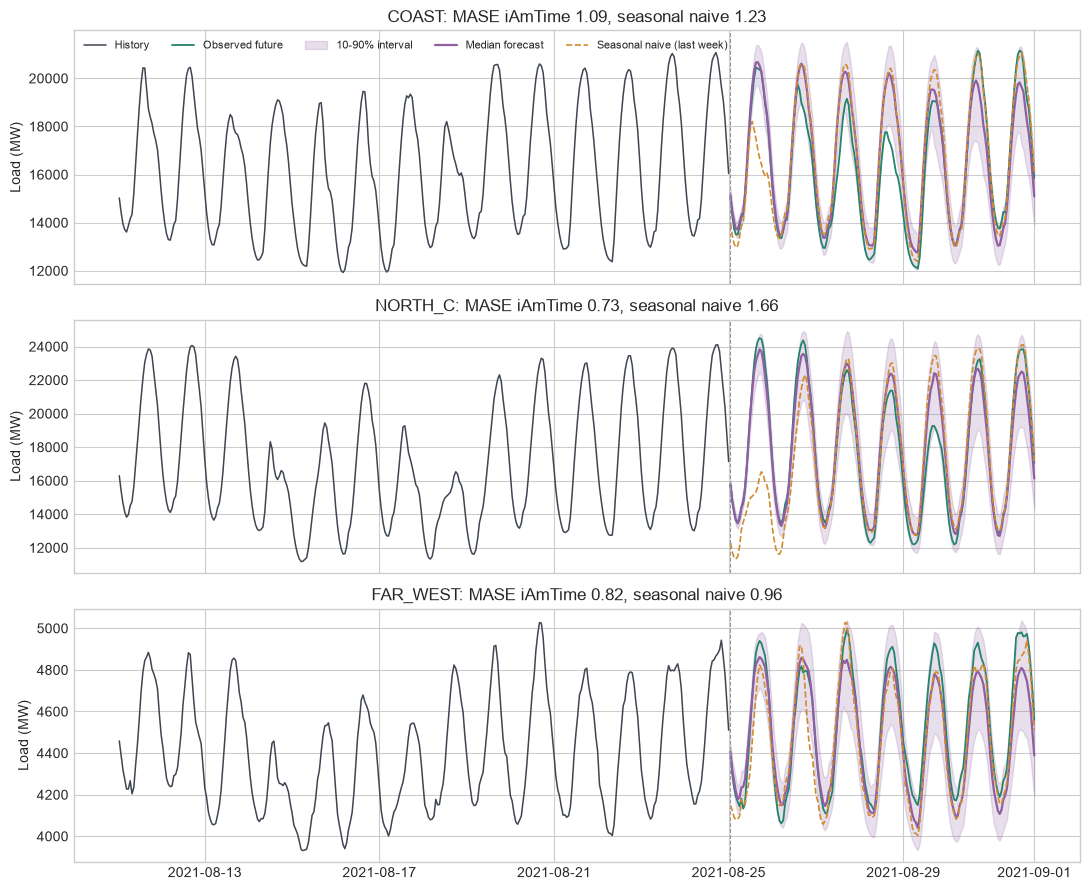

In [5]:
HOURLY_HORIZON = WEEK
HOURLY_CONTEXT = 8 * WEEK
ERCOT_IDS = ["COAST", "NORTH_C", "FAR_WEST"]

ercot = load_config("ercot_1H")
ercot_ids = ercot["id"].tolist()
ercot_times = pd.DatetimeIndex(ercot["timestamp"].iloc[0])
ercot_load = column_matrix(ercot, "target")
print(f"{len(ercot_ids)} zones: {', '.join(ercot_ids)}; {ercot_times[0]} to {ercot_times[-1]}")

origin = len(ercot_times) - HOURLY_HORIZON
zone_rows = [ercot_ids.index(zone) for zone in ERCOT_IDS]
uni_input = ercot_load[zone_rows, origin - HOURLY_CONTEXT:origin]
uni_quantiles = predict(uni_input, HOURLY_HORIZON)

fig, axes = plt.subplots(len(ERCOT_IDS), 1, figsize=(11, 3.0 * len(ERCOT_IDS)), sharex=True)
for ax, row, quantiles in zip(axes, zone_rows, uni_quantiles):
    context = ercot_load[row, origin - HOURLY_CONTEXT:origin]
    truth = ercot_load[row, origin:origin + HOURLY_HORIZON]
    naive = seasonal_naive(context, HOURLY_HORIZON, WEEK)
    plot_forecast(ax, ercot_times[origin - 2 * WEEK:origin], context[-2 * WEEK:], ercot_times[origin:origin + HOURLY_HORIZON], truth, quantiles,
                  f"{ercot_ids[row]}: MASE iAmTime {mase(context, truth, quantiles[:, 1], DAY):.2f}, seasonal naive {mase(context, truth, naive, DAY):.2f}",
                  reference=naive, reference_label="Seasonal naive (last week)", ylabel="Load (MW)")
axes[0].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "01_univariate")
plt.show()

### 1b. Scorecard: iAmTime vs. seasonal naive

All 8 zones, 8 forecast origins spaced 6 weeks apart over the last year of data (64 one-week forecasts), each with the same 8-week context.

In [6]:
score_origins = [len(ercot_times) - HOURLY_HORIZON - k * 6 * WEEK for k in range(8)]
score_pairs = [(row, o) for row in range(len(ercot_ids)) for o in score_origins]
score_quantiles = predict(np.stack([ercot_load[row, o - HOURLY_CONTEXT:o] for row, o in score_pairs]), HOURLY_HORIZON)

def ercot_score(row, o, forecast):
    return mase(ercot_load[row, o - HOURLY_CONTEXT:o], ercot_load[row, o:o + HOURLY_HORIZON], forecast, DAY)

uni_scores = pd.DataFrame({
    "seasonal naive (last week)": [ercot_score(row, o, seasonal_naive(ercot_load[row, o - HOURLY_CONTEXT:o], HOURLY_HORIZON, WEEK)) for row, o in score_pairs],
    "iAmTime zero-shot": [ercot_score(row, o, q[:, 1]) for (row, o), q in zip(score_pairs, score_quantiles)],
})
scorecard(uni_scores, reference="seasonal naive (last week)")

,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
reference: seasonal naive (last week),,,,,,
seasonal naive (last week),1.480,"[1.350, 1.645]",1.285,NaN,0.000,"[0.000, 0.000]"
iAmTime zero-shot,0.913,"[0.835, 1.000]",0.856,0.938,-0.567,"[-0.686, -0.465]"


**Result.** iAmTime beats the weekly seasonal naive forecast on 94 % of the 64 forecasts (mean MASE 0.91 vs 1.48). Seasonal naive fails whenever last week was unusual, for example a cooler week or a holiday (visible in the NORTH_C panel above), while the model blends the whole 8-week context.

## 2. Multivariate forecasting: transformer loads and oil temperature

**Data.** `ETT_1H`: two electricity transformers (ETTh1, ETTh2), hourly, 2016–2018. Each has six load channels (high/middle/low useful and useless load: `HUFL`, `HULL`, `MUFL`, `MULL`, `LUFL`, `LULL`) and the oil temperature `OT`. fev-bench forecasts all seven channels together.

**Input card.** A three-dimensional array with shape `(batch, variates, context)`; the output gains a variate axis:

```python
multi_input = ett_values[0][None, :, origin - HOURLY_CONTEXT:origin]      # (1, 7, 1344)
quantiles, _ = pipeline.predict_quantiles(multi_input, prediction_length=168, quantile_levels=[0.1, 0.5, 0.9])
# quantiles: (1, 7, 168, 3)
```

iAmTime forecasts every channel and uses the other channels as additional context.

**How to read the figure.** Three of the seven channels of ETTh1 for the last week of data. Solid purple = joint forecast; **dashed orange = the same channel forecast on its own**. The title shows both MASE values.

['ETTh1', 'ETTh2']: 7 channels, 2016-07-01 00:00:00 to 2018-06-26 19:00:00
Correlation of the ETTh1 channels over the context:
      HUFL  HULL  MUFL  MULL  LUFL  LULL    OT
HUFL  1.00  0.22  0.99  0.21  0.50  0.01 -0.23
HULL  0.22  1.00  0.17  0.96  0.46  0.51 -0.06
MUFL  0.99  0.17  1.00  0.17  0.40 -0.08 -0.24
MULL  0.21  0.96  0.17  1.00  0.33  0.37 -0.10
LUFL  0.50  0.46  0.40  0.33  1.00  0.63  0.00
LULL  0.01  0.51 -0.08  0.37  0.63  1.00  0.20
OT   -0.23 -0.06 -0.24 -0.10  0.00  0.20  1.00


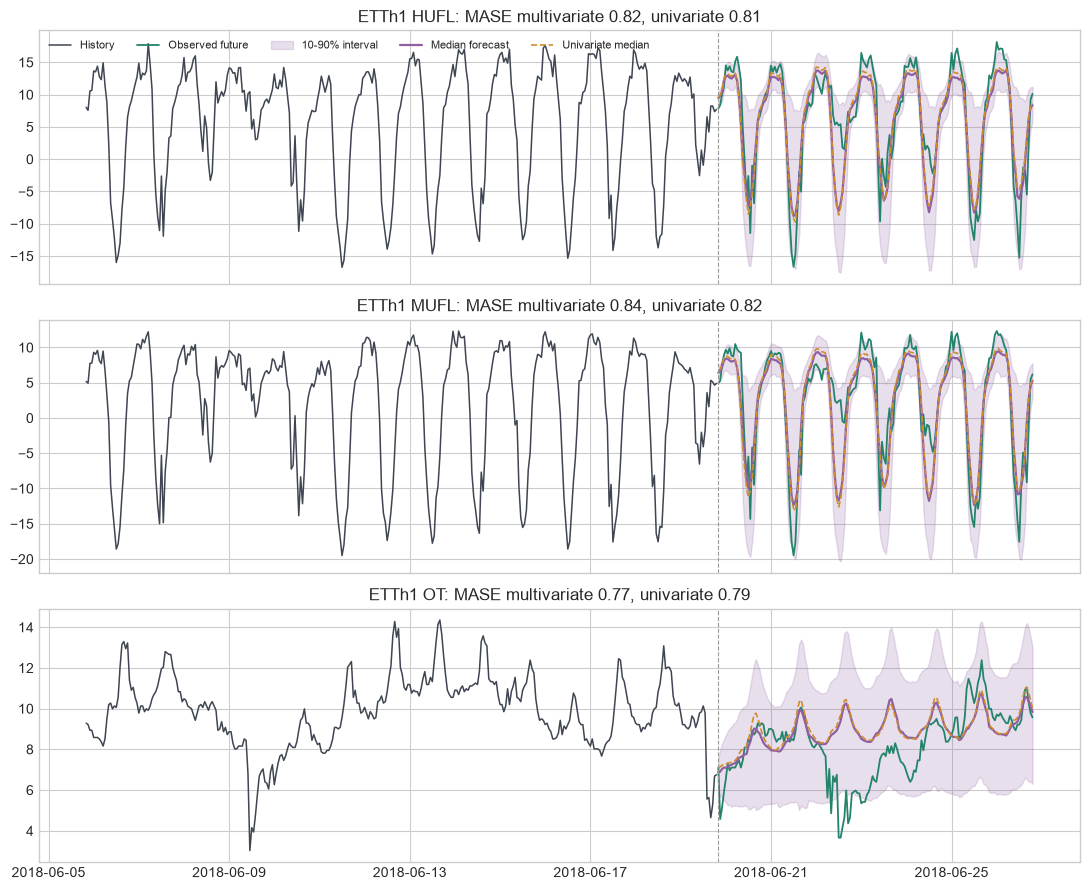

In [7]:
ETT_CHANNELS = ["HUFL", "HULL", "MUFL", "MULL", "LUFL", "LULL", "OT"]
ETT_PLOT_CHANNELS = ["HUFL", "MUFL", "OT"]

ett = load_config("ETT_1H")
ett_ids = ett["id"].tolist()
ett_times = pd.DatetimeIndex(ett["timestamp"].iloc[0])
ett_values = np.stack([column_matrix(ett, channel) for channel in ETT_CHANNELS], axis=1)  # (transformers, 7, time)
print(f"{ett_ids}: {ett_values.shape[1]} channels, {ett_times[0]} to {ett_times[-1]}")

origin = len(ett_times) - HOURLY_HORIZON
context = ett_values[0, :, origin - HOURLY_CONTEXT:origin]
print("Correlation of the ETTh1 channels over the context:")
print(pd.DataFrame(np.corrcoef(context), index=ETT_CHANNELS, columns=ETT_CHANNELS).round(2).to_string())

multi_quantiles = predict(context[None], HOURLY_HORIZON)[0]    # Joint: (7, 168, 3)
single_quantiles = predict(context, HOURLY_HORIZON)            # Each channel alone.

fig, axes = plt.subplots(len(ETT_PLOT_CHANNELS), 1, figsize=(11, 3.0 * len(ETT_PLOT_CHANNELS)), sharex=True)
for ax, channel in zip(axes, ETT_PLOT_CHANNELS):
    c = ETT_CHANNELS.index(channel)
    truth = ett_values[0, c, origin:origin + HOURLY_HORIZON]
    plot_forecast(ax, ett_times[origin - 2 * WEEK:origin], context[c, -2 * WEEK:], ett_times[origin:origin + HOURLY_HORIZON], truth, multi_quantiles[c],
                  f"ETTh1 {channel}: MASE multivariate {mase(context[c], truth, multi_quantiles[c][:, 1], DAY):.2f}, "
                  f"univariate {mase(context[c], truth, single_quantiles[c][:, 1], DAY):.2f}",
                  reference=single_quantiles[c][:, 1], reference_label="Univariate median")
axes[0].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "02_multivariate")
plt.show()

### 2b. Scorecard: joint vs. separate

Both transformers, 10 forecast origins spaced 4 weeks apart (20 joint forecasts, 140 channel forecasts), each with an 8-week context.

In [8]:
ett_origins = [len(ett_times) - HOURLY_HORIZON - k * 4 * WEEK for k in range(10)]
ett_contexts = np.stack([ett_values[t, :, o - HOURLY_CONTEXT:o] for t in range(len(ett_ids)) for o in ett_origins])   # (20, 7, ctx)
ett_truths = np.stack([ett_values[t, :, o:o + HOURLY_HORIZON] for t in range(len(ett_ids)) for o in ett_origins])
joint = predict(ett_contexts, HOURLY_HORIZON)                                                                   # (20, 7, 168, 3)
separate = predict(ett_contexts.reshape(-1, HOURLY_CONTEXT), HOURLY_HORIZON).reshape(joint.shape)

flat = lambda a: a.reshape(-1, *a.shape[2:])
multi_scores = pd.DataFrame({
    "univariate (each channel alone)": [mase(h, y, q[:, 1], DAY) for h, y, q in zip(flat(ett_contexts), flat(ett_truths), flat(separate))],
    "multivariate (joint)": [mase(h, y, q[:, 1], DAY) for h, y, q in zip(flat(ett_contexts), flat(ett_truths), flat(joint))],
    "channel": ETT_CHANNELS * len(ett_contexts),
})
print("Mean MASE per channel:")
print(multi_scores.groupby("channel").mean().loc[ETT_CHANNELS].round(3).T.to_string())
scorecard(multi_scores.drop(columns="channel"), reference="univariate (each channel alone)")

Mean MASE per channel:
channel                           HUFL   HULL   MUFL   MULL   LUFL   LULL     OT
univariate (each channel alone)  1.120  1.197  1.097  0.994  1.118  1.021  1.241
multivariate (joint)             1.074  1.191  1.059  0.978  1.130  0.980  1.316


,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
reference: univariate (each channel alone),,,,,,
univariate (each channel alone),1.113,"[1.015, 1.233]",0.959,NaN,0.000,"[0.000, 0.000]"
multivariate (joint),1.104,"[1.003, 1.226]",0.939,0.55,-0.008,"[-0.030, 0.013]"


**Result.** Joint forecasting changes little on this data: mean MASE 1.10 vs 1.11, a win on 55 % of channel forecasts, and a CI on the difference that includes 0. It helps the strongly correlated load pairs (HUFL/MUFL, MULL/LULL) slightly and hurts the oil temperature `OT`, which barely correlates with the loads over a few weeks.

## 3. Forecasting with exogenous variables: day-ahead electricity prices

**Data.** `epf_*`: hourly day-ahead electricity prices (€/MWh, $/MWh for PJM) of five markets, each with two covariates published **before** the day-ahead auction: a load forecast and a generation forecast (for Germany: the Amprion zonal load forecast and the national solar + wind forecast). Unlike weather or macro covariates, these future values really are known at forecast time, so this setup is not optimistic.

**Input card.** A dictionary per market; covariate names may differ between markets in the same batch:

```python
{
    "target": price[origin - 672:origin],                                               # (672,): 4 weeks of hourly prices
    "past_covariates":   {"Ampirion Load Forecast": ..., "PV+Wind Forecast": ...},     # each (672,)
    "future_covariates": {"Ampirion Load Forecast": ..., "PV+Wind Forecast": ...},     # each (24,): the next day
}
```

**How to read the figure.** Top: the German price for the last week of the context and the next day; solid = forecast with covariates, **dashed = without**. Below: the two covariates over the same period (GW). Prices fall when renewable generation is high relative to load (the merit-order effect), and the forecast with covariates can anticipate that for the next day.

epf_be: 2011-01-09 00:00:00 to 2016-12-31 23:00:00; covariates ['Generation forecast', 'System load forecast']


epf_de: 2012-01-09 00:00:00 to 2017-12-31 23:00:00; covariates ['Ampirion Load Forecast', 'PV+Wind Forecast']


epf_fr: 2011-01-09 00:00:00 to 2016-12-31 23:00:00; covariates ['Generation forecast', 'System load forecast']


epf_np: 2013-01-01 00:00:00 to 2018-12-24 23:00:00; covariates ['Grid load forecast', 'Wind power forecast']


epf_pjm: 2013-01-01 00:00:00 to 2018-12-24 23:00:00; covariates ['System load forecast', 'Zonal COMED load foecast']


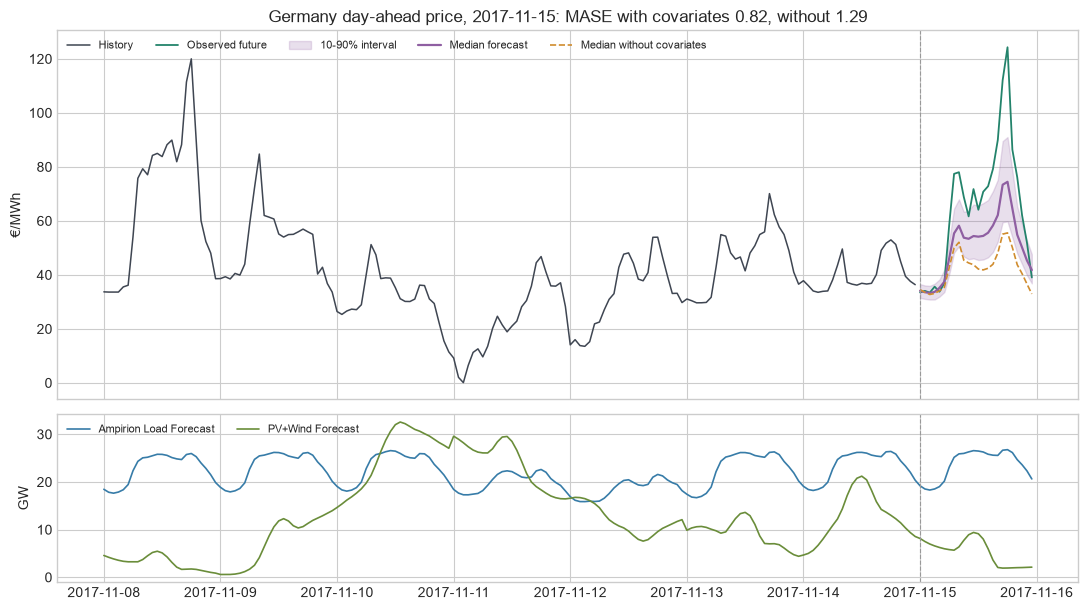

In [9]:
EPF_MARKETS = ["be", "de", "fr", "np", "pjm"]
EPF_HORIZON = DAY
EPF_CONTEXT = 4 * WEEK
EPF_HERO_MARKET = "de"
EPF_HERO_ORIGIN = pd.Timestamp("2017-11-15 00:00")

epf = {}
for market in EPF_MARKETS:
    frame = load_config(f"epf_{market}")
    covariate_names = [c for c in frame.columns if c not in ("id", "timestamp", "target")]
    epf[market] = {
        "times": pd.DatetimeIndex(frame["timestamp"].iloc[0]),
        "price": column_matrix(frame, "target")[0],
        "covariates": {name: column_matrix(frame, name)[0] for name in covariate_names},
    }
    print(f"epf_{market}: {epf[market]['times'][0]} to {epf[market]['times'][-1]}; covariates {covariate_names}")

def make_price_input(market, origin, covariates=None):
    data = epf[market]
    covariates = data["covariates"] if covariates is None else covariates
    return {
        "target": data["price"][origin - EPF_CONTEXT:origin],
        "past_covariates": {name: values[origin - EPF_CONTEXT:origin] for name, values in covariates.items()},
        "future_covariates": {name: values[origin:origin + EPF_HORIZON] for name, values in covariates.items()},
    }

hero = epf[EPF_HERO_MARKET]
hero_origin = int(np.flatnonzero(hero["times"] == EPF_HERO_ORIGIN)[0])
with_cov, without_cov = predict([make_price_input(EPF_HERO_MARKET, hero_origin), {"target": hero["price"][hero_origin - EPF_CONTEXT:hero_origin]}], EPF_HORIZON)
hero_context = hero["price"][hero_origin - EPF_CONTEXT:hero_origin]
hero_truth = hero["price"][hero_origin:hero_origin + EPF_HORIZON]
window = slice(hero_origin - WEEK, hero_origin + EPF_HORIZON)

fig, axes = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
plot_forecast(axes[0], hero["times"][hero_origin - WEEK:hero_origin], hero_context[-WEEK:], hero["times"][hero_origin:hero_origin + EPF_HORIZON], hero_truth, with_cov,
              f"Germany day-ahead price, {EPF_HERO_ORIGIN.date()}: MASE with covariates {mase(hero_context, hero_truth, with_cov[:, 1], DAY):.2f}, "
              f"without {mase(hero_context, hero_truth, without_cov[:, 1], DAY):.2f}",
              reference=without_cov[:, 1], reference_label="Median without covariates", ylabel="€/MWh")
axes[0].legend(ncol=5, frameon=False, loc="upper left", fontsize=8)
for (name, values), color in zip(hero["covariates"].items(), ["#377ca8", "#6a8d3a"]):
    axes[1].plot(hero["times"][window], values[window] / 1000, color=color, lw=1.2, label=name)
axes[1].axvline(hero["times"][hero_origin], color="#999999", lw=0.8, ls="--")
axes[1].set_ylabel("GW")
axes[1].legend(ncol=2, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "03_exogenous_prices")
plt.show()

### 3a. Scorecard: with vs. without covariates

All five markets, 24 forecast origins (midnight, spaced 15 days apart over each market's last year), 120 day-ahead forecasts.

In [10]:
price_pairs = []
for market in EPF_MARKETS:
    times = epf[market]["times"]
    last_midnight = int(np.flatnonzero(times.hour == 0)[-1])
    price_pairs += [(market, last_midnight - EPF_HORIZON - k * 15 * DAY) for k in range(24)]

no_cov_quantiles = predict([{"target": epf[m]["price"][o - EPF_CONTEXT:o]} for m, o in price_pairs], EPF_HORIZON)
cov_quantiles = predict([make_price_input(m, o) for m, o in price_pairs], EPF_HORIZON)

def price_score(market, o, forecast):
    price = epf[market]["price"]
    return mase(price[o - EPF_CONTEXT:o], price[o:o + EPF_HORIZON], forecast, DAY)

price_scores = pd.DataFrame({
    "seasonal naive (same hour yesterday)": [price_score(m, o, seasonal_naive(epf[m]["price"][o - EPF_CONTEXT:o], EPF_HORIZON, DAY)) for m, o in price_pairs],
    "iAmTime without covariates": [price_score(m, o, q[:, 1]) for (m, o), q in zip(price_pairs, no_cov_quantiles)],
    "iAmTime with load + generation forecasts": [price_score(m, o, q[:, 1]) for (m, o), q in zip(price_pairs, cov_quantiles)],
}, index=pd.MultiIndex.from_tuples(price_pairs, names=["market", "origin"]))
print("Mean MASE per market:")
print(price_scores.groupby(level="market").mean().round(3).to_string())
scorecard(price_scores.reset_index(drop=True), reference="iAmTime without covariates")

Mean MASE per market:
        seasonal naive (same hour yesterday)  iAmTime without covariates  iAmTime with load + generation forecasts
market                                                                                                            
be                                     1.002                       0.648                                     0.576
de                                     0.739                       0.503                                     0.349
fr                                     0.991                       0.585                                     0.483
np                                     0.933                       0.622                                     0.541
pjm                                    0.924                       0.641                                     0.569


,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
reference: iAmTime without covariates,,,,,,
seasonal naive (same hour yesterday),0.918,"[0.806, 1.028]",0.731,0.258,0.318,"[0.238, 0.399]"
iAmTime without covariates,0.600,"[0.528, 0.672]",0.476,NaN,0.000,"[0.000, 0.000]"
iAmTime with load + generation forecasts,0.504,"[0.436, 0.581]",0.388,0.700,-0.096,"[-0.139, -0.054]"


**Result.** The day-ahead load and generation forecasts lower the error in every market (mean MASE 0.50 vs 0.60, a win on 70 % of days); the gain is largest in Germany (0.35 vs 0.50), where wind and solar move prices most. Both iAmTime variants are far ahead of the same-hour-yesterday baseline.

### 3b. What-if: more or less renewable generation

Because future covariates are inputs, you can ask **"what if"** questions by changing them: every scenario is just another row in the batch. Here the German next-day solar + wind forecast is scaled by 0.5x to 1.5x while the load forecast is kept, and the model's price forecast is compared with the unchanged (1x) scenario.

These are counterfactuals on real data, so **there is no observed truth** for them. As a reference, the dose–response plot in 3c shows the slope a simple linear regression of price on load and renewables (with hour-of-day effects) finds in the same 4-week context: roughly how much the price moved per GW of renewables in the recent past.

**How to read the figure.** Median price forecasts for each scenario; the observed price (which belongs to the 1x scenario) in green.

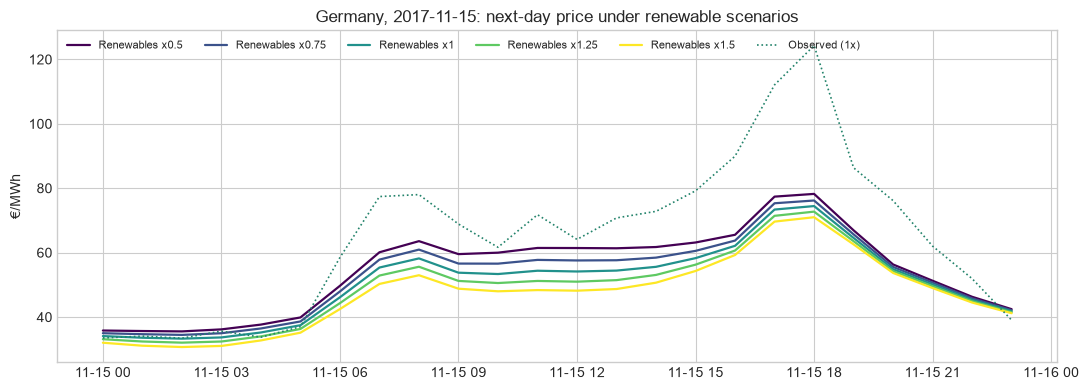

In [11]:
RENEWABLE_COLUMN = "PV+Wind Forecast"
RENEWABLE_SCALES = [0.5, 0.75, 1.0, 1.25, 1.5]

def scaled_covariates(scale):
    covariates = dict(hero["covariates"])
    renewables = covariates[RENEWABLE_COLUMN].copy()
    renewables[hero_origin:hero_origin + EPF_HORIZON] *= scale
    covariates[RENEWABLE_COLUMN] = renewables
    return covariates

scenario_quantiles = predict([make_price_input(EPF_HERO_MARKET, hero_origin, scaled_covariates(s)) for s in RENEWABLE_SCALES], EPF_HORIZON)
base_median = scenario_quantiles[RENEWABLE_SCALES.index(1.0)][:, 1]

fig, ax = plt.subplots(figsize=(11, 4))
future_times = hero["times"][hero_origin:hero_origin + EPF_HORIZON]
cmap = plt.get_cmap("viridis")
for k, (scale, quantiles) in enumerate(zip(RENEWABLE_SCALES, scenario_quantiles)):
    ax.plot(future_times, quantiles[:, 1], color=cmap(k / (len(RENEWABLE_SCALES) - 1)), lw=1.6, label=f"Renewables x{scale:g}")
ax.plot(future_times, hero_truth, color=COLORS["truth"], lw=1.2, ls=":", label="Observed (1x)")
ax.set_ylabel("€/MWh")
ax.set_title(f"Germany, {EPF_HERO_ORIGIN.date()}: next-day price under renewable scenarios")
ax.legend(ncol=6, frameon=False, loc="upper left", fontsize=8)
plt.tight_layout()
savefig(fig, "03_renewable_scenarios")
plt.show()

### 3c. Dose–response: renewables vs. price

x-axis: change in mean next-day renewable generation (GW); y-axis: change in mean predicted price relative to the 1x scenario. The dashed line is the historical slope from the regression described above. A forecast that follows the merit-order effect slopes downward; agreement with the historical slope says the model's sensitivity is in a plausible range.

       renewable change (GW)  predicted price change (€/MWh)
scale                                                       
0.50                   -2.67                            3.73
0.75                   -1.34                            1.81
1.00                    0.00                            0.00
1.25                    1.34                           -1.72
1.50                    2.67                           -3.38
Historical slope: -2.02 €/MWh per GW of renewables; model slope (0.5x to 1.5x): -1.33 €/MWh per GW


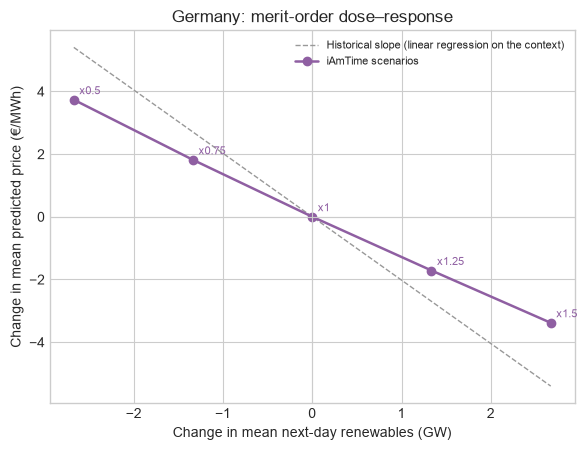

In [12]:
renewables = hero["covariates"][RENEWABLE_COLUMN]
future_renewables = renewables[hero_origin:hero_origin + EPF_HORIZON]
dose = pd.DataFrame({
    "renewable change (GW)": [(s - 1.0) * future_renewables.mean() / 1000 for s in RENEWABLE_SCALES],
    "predicted price change (€/MWh)": [(q[:, 1] - base_median).mean() for q in scenario_quantiles],
}, index=pd.Index(RENEWABLE_SCALES, name="scale"))

# Historical slope: price ~ load + renewables + hour-of-day, over the 4-week context.
ctx = slice(hero_origin - EPF_CONTEXT, hero_origin)
hours = hero["times"][ctx].hour
design = np.column_stack([
    hero["covariates"]["Ampirion Load Forecast"][ctx] / 1000,
    renewables[ctx] / 1000,
    *[(hours == h).astype(float) for h in range(24)],
])
coefficients, *_ = np.linalg.lstsq(design, hero["price"][ctx], rcond=None)
historical_slope = coefficients[1]
print(dose.round(2).to_string())
print(f"Historical slope: {historical_slope:.2f} €/MWh per GW of renewables; "
      f"model slope (0.5x to 1.5x): {np.polyfit(dose.iloc[:, 0], dose.iloc[:, 1], 1)[0]:.2f} €/MWh per GW")

fig, ax = plt.subplots(figsize=(6, 4.6))
x = dose["renewable change (GW)"].to_numpy()
ax.plot(x, historical_slope * x, color="#999999", lw=1.0, ls="--", label="Historical slope (linear regression on the context)")
ax.plot(x, dose["predicted price change (€/MWh)"], "o-", color=COLORS["forecast"], lw=1.8, label="iAmTime scenarios")
for scale, (gw, change) in dose.iterrows():
    ax.annotate(f"x{scale:g}", (gw, change), xytext=(4, 4), textcoords="offset points", fontsize=8, color=COLORS["forecast"])
ax.axhline(0, color="#cccccc", lw=0.8)
ax.axvline(0, color="#cccccc", lw=0.8)
ax.set_xlabel("Change in mean next-day renewables (GW)")
ax.set_ylabel("Change in mean predicted price (€/MWh)")
ax.set_title("Germany: merit-order dose–response")
ax.legend(frameon=False, fontsize=8, loc="upper right")
plt.tight_layout()
savefig(fig, "03_dose_response")
plt.show()

**Result.** The model's price response is monotone and has the merit-order sign: about −1.3 €/MWh per additional GW of renewables, against −2.0 €/MWh per GW from the historical regression. The model is somewhat more conservative than the regression, and the response is roughly linear over 0.5x to 1.5x. Without observed counterfactuals this is a plausibility check, not a validation.

## 4. Forecasting with examples: national load around holidays and seasons

The full ICL input supplies completed **support examples** before the query. Each example has a target history and its observed future; the model treats them as demonstrations of how series like the query behave, without fine-tuning.

**Data.** `entsoe_1H` aggregated to **daily national load** (GWh) for six countries (AT, BE, DE, HU, LU, NL), 2015–2019.

**Input card.**

```python
{
    "example_target_histories": [hist_1, ..., hist_k],   # each (56,)  completed demonstrations
    "example_target_futures":   [fut_1,  ..., fut_k],    # each (28,)
    "query_target_history":     hist_q,                  # (56,)       the series to forecast
}
```

**Design.** The query sees only its last **56 days**, too short to show yearly effects such as the Christmas dip or the shift into the heating season. Each example is the **same 56 + 28-day calendar window in an earlier year** (shifted by multiples of 364 days, which keeps weekdays aligned), taken from:

- the query country's own past years (most recent first), then
- other countries' past years, ranked by how closely their window matched the query's own window one year earlier (z-normalised shape).

Everything ends before the query's forecast origin, so there is no leakage. With a multi-year history, zero-shot forecasting already captures these yearly effects; this section deliberately uses a short context to show what the examples add.

| § | Question | Format |
|---|---|---|
| 4a | What does one forecast look like? | Christmas 2019 in Germany |
| 4b | What does the model actually see? | prompt-anatomy figure |
| 4c | Do examples help, and which ones? | scorecard on 256 forecasts + ladder with a shuffled-futures **control** |
| 4d | How does the error change with the number of examples? | k-shot curve, k = 0 to 12 |
| 4e | Cold start | a new market with 14 days of history and examples from other countries |

In [13]:
DAILY_HORIZON = 28
DAILY_CONTEXT = 56
YEAR = 364  # Days; a multiple of 7 keeps weekdays aligned across years.

entsoe = load_config("entsoe_1H")
entsoe_ids = entsoe["id"].tolist()
hourly_times = pd.DatetimeIndex(entsoe["timestamp"].iloc[0])
hourly_load = column_matrix(entsoe, "target")
first_midnight = int(np.flatnonzero(hourly_times.hour == 0)[0])
num_days = (hourly_load.shape[1] - first_midnight) // DAY
daily_load = hourly_load[:, first_midnight:first_midnight + num_days * DAY].reshape(len(entsoe_ids), num_days, DAY).sum(axis=2) / 1000  # GWh
days = pd.date_range(hourly_times[first_midnight].normalize(), periods=num_days, freq="D")
print(f"{len(entsoe_ids)} countries: {', '.join(entsoe_ids)}; {days[0].date()} to {days[-1].date()} ({num_days} days)")

def season_profile(row, end):
    window = daily_load[row, end:end + DAILY_HORIZON]
    return (window - window.mean()) / max(window.std(), 1e-6)

def example_pool(row, origin, years=(1, 2, 3)):
    # (row, example_origin) pairs: own past years first, then other countries' past years by season similarity.
    own = [(row, origin - k * YEAR) for k in years if origin - k * YEAR - DAILY_CONTEXT >= 0]
    others = [(r, origin - k * YEAR) for r in range(len(entsoe_ids)) if r != row for k in years if origin - k * YEAR - DAILY_CONTEXT >= 0]
    reference = season_profile(row, origin - YEAR)
    others.sort(key=lambda source: np.linalg.norm(season_profile(*source) - reference))
    return own, others

def make_example_input(row, origin, sources, query_context=DAILY_CONTEXT, example_context=DAILY_CONTEXT, shuffle_futures=False):
    query = daily_load[row, origin - query_context:origin]
    if not sources:
        return {"query_target_history": query}
    futures = [daily_load[r, o:o + DAILY_HORIZON] for r, o in sources]
    if shuffle_futures:
        futures = futures[1:] + futures[:1]  # Every history gets another example's future.
    return {
        "example_target_histories": [daily_load[r, o - example_context:o] for r, o in sources],
        "example_target_futures": futures,
        "query_target_history": query,
    }

def daily_score(row, origin, forecast, query_context=DAILY_CONTEXT):
    return mase(daily_load[row, origin - query_context:origin], daily_load[row, origin:origin + DAILY_HORIZON], forecast, 7)

6 countries: AT, BE, DE, HU, LU, NL; 2015-01-02 to 2019-12-30 (1824 days)


### 4a. Christmas in Germany

The query is Germany's daily load from 2019-12-02, so the 28-day horizon contains Christmas and the days between Christmas and New Year, when industrial load drops sharply. The 56-day context (October–November) contains no holiday of that size. The examples are Germany's own same window in 2016, 2017 and 2018.

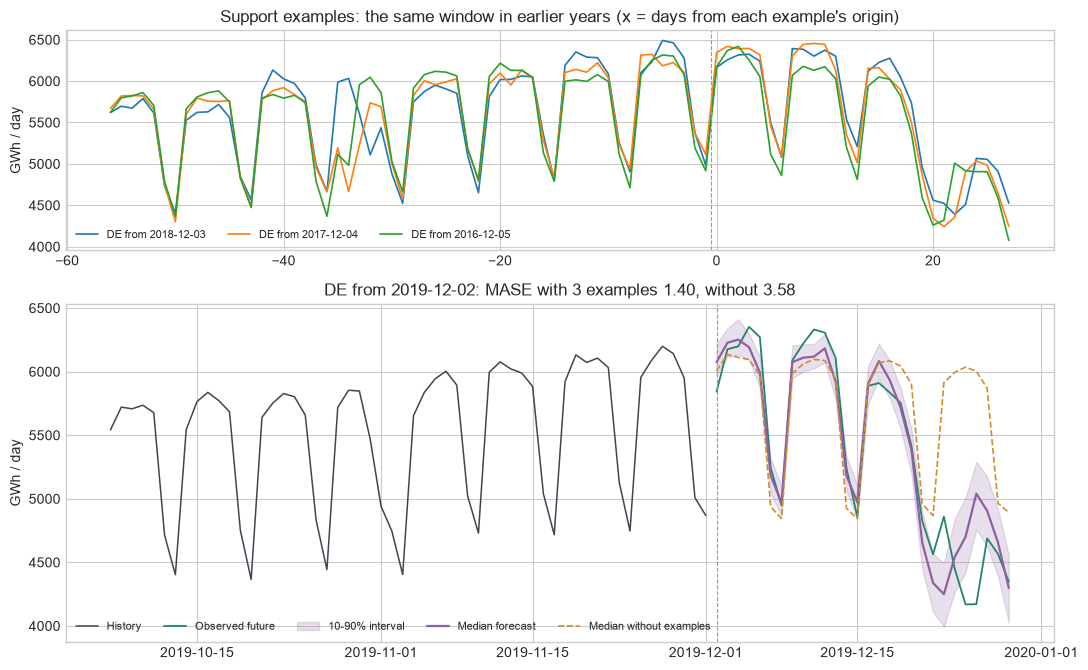

In [14]:
HERO_COUNTRY = "DE"
HERO_ORIGIN = pd.Timestamp("2019-12-02")

hero_row = entsoe_ids.index(HERO_COUNTRY)
hero_day = int(np.flatnonzero(days == HERO_ORIGIN)[0])
hero_sources, _ = example_pool(hero_row, hero_day)
example_quantiles, zero_quantiles = predict([
    make_example_input(hero_row, hero_day, hero_sources),
    make_example_input(hero_row, hero_day, []),
], DAILY_HORIZON)
hero_context = daily_load[hero_row, hero_day - DAILY_CONTEXT:hero_day]
hero_truth = daily_load[hero_row, hero_day:hero_day + DAILY_HORIZON]
future_days = days[hero_day:hero_day + DAILY_HORIZON]

fig, axes = plt.subplots(2, 1, figsize=(11, 6.8), gridspec_kw={"height_ratios": [1.3, 2.0]})
for r, o in hero_sources:
    window = daily_load[r, o - DAILY_CONTEXT:o + DAILY_HORIZON]
    axes[0].plot(np.arange(-DAILY_CONTEXT, DAILY_HORIZON), window, lw=1.2, label=f"{entsoe_ids[r]} from {days[o].date()}")
axes[0].axvline(-0.5, color="#999999", lw=0.8, ls="--")
axes[0].set_title("Support examples: the same window in earlier years (x = days from each example's origin)")
axes[0].set_ylabel("GWh / day")
axes[0].legend(ncol=3, frameon=False, loc="lower left", fontsize=8)

plot_forecast(axes[1], days[hero_day - DAILY_CONTEXT:hero_day], hero_context, future_days, hero_truth, example_quantiles,
              f"{HERO_COUNTRY} from {HERO_ORIGIN.date()}: MASE with 3 examples {daily_score(hero_row, hero_day, example_quantiles[:, 1]):.2f}, "
              f"without {daily_score(hero_row, hero_day, zero_quantiles[:, 1]):.2f}",
              reference=zero_quantiles[:, 1], reference_label="Median without examples", ylabel="GWh / day")
axes[1].legend(ncol=5, frameon=False, loc="lower left", fontsize=8)
plt.tight_layout()
savefig(fig, "04a_christmas")
plt.show()

### 4b. Prompt anatomy: what the model actually sees

The same input as 4a, drawn the way the model receives it: three completed examples (history → observed future), then the query (history → **?**). The x-axis is days from each block's forecast origin, so the three earlier Decembers and the query's December line up.

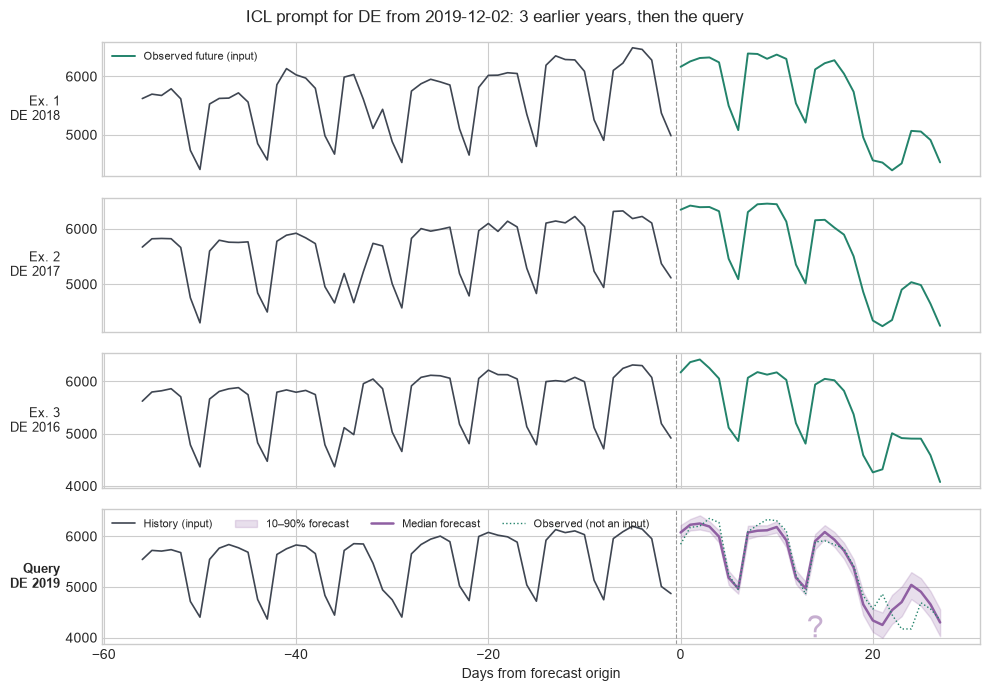

In [15]:
def plot_prompt_anatomy(row, origin, sources, quantiles, title, name=None, query_context=DAILY_CONTEXT, example_context=DAILY_CONTEXT):
    rows = len(sources) + 1
    fig, axes = plt.subplots(rows, 1, figsize=(10, 1.55 * rows + 0.8), sharex=True)
    future_x = np.arange(0, DAILY_HORIZON)
    for k, (ax, (r, o)) in enumerate(zip(axes, sources)):
        ax.plot(np.arange(-example_context, 0), daily_load[r, o - example_context:o], color=COLORS["history"], lw=1.2)
        ax.plot(future_x, daily_load[r, o:o + DAILY_HORIZON], color=COLORS["truth"], lw=1.4)
        ax.set_ylabel(f"Ex. {k + 1}\n{entsoe_ids[r]} {days[o].year}", rotation=0, ha="right", va="center", fontsize=9)
    ax = axes[-1]
    ax.plot(np.arange(-query_context, 0), daily_load[row, origin - query_context:origin], color=COLORS["history"], lw=1.2, label="History (input)")
    ax.fill_between(future_x, quantiles[:, 0], quantiles[:, 2], color=COLORS["forecast"], alpha=0.2, label="10–90% forecast")
    ax.plot(future_x, quantiles[:, 1], color=COLORS["forecast"], lw=1.8, label="Median forecast")
    ax.plot(future_x, daily_load[row, origin:origin + DAILY_HORIZON], color=COLORS["truth"], lw=1.0, ls=":", label="Observed (not an input)")
    ax.set_ylabel(f"Query\n{entsoe_ids[row]} {days[origin].year}", rotation=0, ha="right", va="center", fontsize=9, fontweight="bold")
    ax.text(DAILY_HORIZON / 2, 0.05, "?", transform=ax.get_xaxis_transform(), ha="center", fontsize=22, color=COLORS["forecast"], alpha=0.5)
    ax.legend(ncol=4, frameon=False, loc="upper left", fontsize=8)
    ax.set_xlabel("Days from forecast origin")
    for ax in axes:
        ax.axvline(-0.5, color="#999999", lw=0.8, ls="--")
    axes[0].plot([], [], color=COLORS["truth"], lw=1.4, label="Observed future (input)")
    axes[0].legend(frameon=False, loc="upper left", fontsize=8)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    if name:
        savefig(fig, name)
    plt.show()

plot_prompt_anatomy(hero_row, hero_day, hero_sources, example_quantiles,
                    f"ICL prompt for {HERO_COUNTRY} from {HERO_ORIGIN.date()}: 3 earlier years, then the query", name="04b_prompt_anatomy")

### 4c. Scorecard: do examples help, and which ones?

256 random (country, origin) forecasts with weekly origins from February 2018 to November 2019, so every query has three earlier years available. Variants:

- zero-shot from the same 56 days (the **reference**),
- 1 example: the query country one year earlier,
- 3 examples: the query country one, two and three years earlier,
- 5 examples: the query country's 3 years plus the 2 best-matching other-country windows,
- 5 examples from **other countries only** (no own past), the situation of a country without its own history,
- **control**: the same 5 examples with their futures rotated, so every history is paired with another example's future. The model sees exactly as much data, but the demonstrated history → future mapping is broken. If this control were as good as the real examples, the benefit would be "more context", not in-context learning.

256 forecasts; origins 2018-02-23 to 2019-11-29


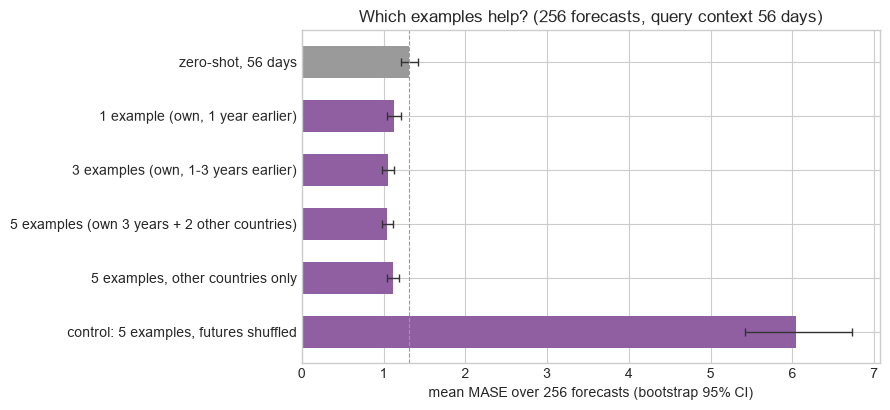

,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
"reference: zero-shot, 56 days",,,,,,
"zero-shot, 56 days",1.315,"[1.212, 1.424]",1.111,NaN,0.000,"[0.000, 0.000]"
"1 example (own, 1 year earlier)",1.125,"[1.047, 1.207]",0.999,0.547,-0.190,"[-0.264, -0.118]"
"3 examples (own, 1-3 years earlier)",1.052,"[0.983, 1.128]",0.902,0.621,-0.263,"[-0.337, -0.191]"
5 examples (own 3 years + 2 other countries),1.047,"[0.978, 1.120]",0.941,0.629,-0.268,"[-0.343, -0.194]"
"5 examples, other countries only",1.114,"[1.045, 1.184]",1.052,0.559,-0.201,"[-0.273, -0.129]"
"control: 5 examples, futures shuffled",6.043,"[5.418, 6.734]",4.459,0.086,4.728,"[4.113, 5.381]"


In [16]:
rng = np.random.default_rng(0)
eval_origins = list(range(3 * YEAR + DAILY_CONTEXT, num_days - DAILY_HORIZON, 7))
all_pairs = [(row, o) for row in range(len(entsoe_ids)) for o in eval_origins]
eval_pairs = [all_pairs[k] for k in rng.choice(len(all_pairs), size=256, replace=False)]
print(f"{len(eval_pairs)} forecasts; origins {days[eval_origins[0]].date()} to {days[eval_origins[-1]].date()}")

def ranked_sources(row, origin):
    own, others = example_pool(row, origin)
    return own + others

icl_variants = {
    "zero-shot, 56 days": [make_example_input(r, o, []) for r, o in eval_pairs],
    "1 example (own, 1 year earlier)": [make_example_input(r, o, ranked_sources(r, o)[:1]) for r, o in eval_pairs],
    "3 examples (own, 1-3 years earlier)": [make_example_input(r, o, ranked_sources(r, o)[:3]) for r, o in eval_pairs],
    "5 examples (own 3 years + 2 other countries)": [make_example_input(r, o, ranked_sources(r, o)[:5]) for r, o in eval_pairs],
    "5 examples, other countries only": [make_example_input(r, o, example_pool(r, o)[1][:5]) for r, o in eval_pairs],
    "control: 5 examples, futures shuffled": [make_example_input(r, o, ranked_sources(r, o)[:5], shuffle_futures=True) for r, o in eval_pairs],
}
icl_results = pd.DataFrame({
    name: [daily_score(r, o, q[:, 1]) for (r, o), q in zip(eval_pairs, predict(inputs, DAILY_HORIZON))]
    for name, inputs in icl_variants.items()
})
REFERENCE = "zero-shot, 56 days"
plot_ladder(icl_results, REFERENCE, f"Which examples help? ({len(icl_results)} forecasts, query context 56 days)", name="04c_relevance_ladder")
scorecard(icl_results, reference=REFERENCE)

**Result.** Every real example variant beats zero-shot from the same 56 days, with CIs on the difference that exclude 0. The query country's own earlier years are the most useful examples (3 own years: mean MASE 1.05 vs 1.32, median 0.90 vs 1.11); two more windows from other countries add nothing on top, and other countries alone still help (1.11). The **shuffled-futures control is catastrophic** (mean MASE above 6): the model reads the history → future pairing in the examples, so wrong demonstrations actively mislead it.

### 4d. Error vs. number of examples

The k-shot curve on the same 256 forecasts: the first `k` sources in the ranking above (own past years first, then other countries by season similarity), for `k = 0, 1, 2, 3, 4, 6, 8, 10, 12`. The checkpoint was trained with up to 6 examples; the shaded region (`k > 6`) is beyond that, and the model accepts it without changes.

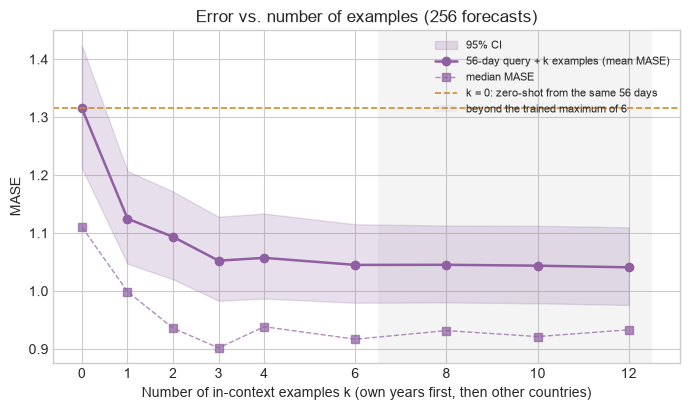

          k=0    k=1    k=2    k=3    k=4    k=6    k=8   k=10   k=12
mean    1.315  1.125  1.093  1.052  1.057  1.045  1.045  1.044  1.041
median  1.111  0.999  0.936  0.902  0.938  0.917  0.932  0.921  0.933


In [17]:
EXAMPLE_COUNTS = [0, 1, 2, 3, 4, 6, 8, 10, 12]
TRAINED_MAX_EXAMPLES = 6

curve_scores = pd.DataFrame({
    f"k={k}": [daily_score(r, o, q[:, 1]) for (r, o), q in zip(eval_pairs, predict([make_example_input(r, o, ranked_sources(r, o)[:k]) for r, o in eval_pairs], DAILY_HORIZON))]
    for k in EXAMPLE_COUNTS
})
rng = np.random.default_rng(0)
idx = rng.integers(0, len(curve_scores), size=(2000, len(curve_scores)))
curve_mean = curve_scores.mean()
curve_ci = np.stack([np.percentile(curve_scores[c].to_numpy()[idx].mean(axis=1), [2.5, 97.5]) for c in curve_scores.columns])

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.fill_between(EXAMPLE_COUNTS, curve_ci[:, 0], curve_ci[:, 1], color=COLORS["forecast"], alpha=0.2, label="95% CI")
ax.plot(EXAMPLE_COUNTS, curve_mean, "o-", color=COLORS["forecast"], lw=1.8, label="56-day query + k examples (mean MASE)")
ax.plot(EXAMPLE_COUNTS, curve_scores.median(), "s--", color=COLORS["forecast"], lw=1.0, alpha=0.7, label="median MASE")
ax.axhline(curve_mean.iloc[0], color=COLORS["reference"], lw=1.2, ls="--", label="k = 0: zero-shot from the same 56 days")
ax.axvspan(TRAINED_MAX_EXAMPLES + 0.5, EXAMPLE_COUNTS[-1] + 0.5, color="#999999", alpha=0.10, lw=0, label="beyond the trained maximum of 6")
ax.set_xticks(EXAMPLE_COUNTS)
ax.set_xlabel("Number of in-context examples k (own years first, then other countries)")
ax.set_ylabel("MASE")
ax.set_title(f"Error vs. number of examples ({len(curve_scores)} forecasts)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
savefig(fig, "04d_example_count_curve")
plt.show()
print(pd.DataFrame({"mean": curve_mean, "median": curve_scores.median()}).round(3).T.to_string())

**Result.** Most of the gain comes from the first three examples, which are the query country's own earlier years; after that the curve is flat. Going beyond the trained maximum of 6 neither helps nor breaks the model.

### 4e. Cold start: a new market with 14 days of history

A new bidding zone, a newly metered region, or a market after a structural break has only a couple of weeks of usable history and no own past years. Other countries' history can stand in for it.

- **Query**: the last `COLD_CONTEXT = 14` days before the origin.
- **Examples**: the 5 best-matching other-country windows from earlier years (ranked as above), each with a 14-day history and the following 28 days. The query's own past is **not** used.

The figure uses the Christmas query of 4a; the scorecard repeats the comparison on the 256 forecasts of 4c.

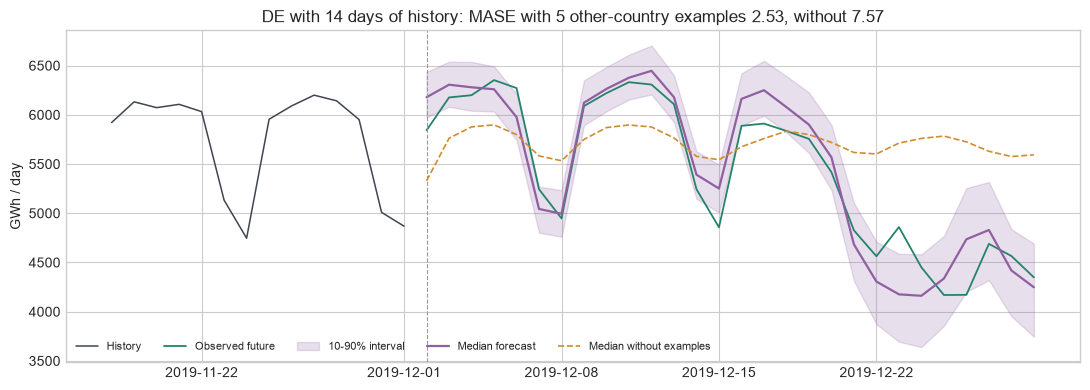

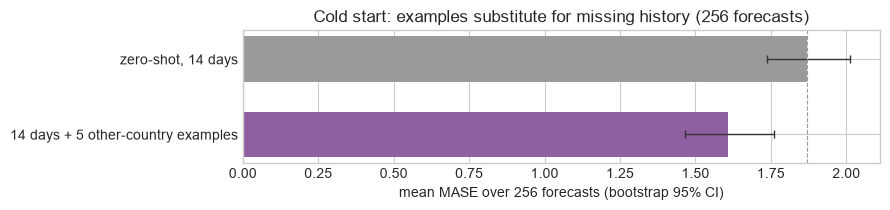

,mean MASE,mean 95% CI,median MASE,win rate vs ref,Δ mean vs ref,Δ 95% CI
"reference: zero-shot, 14 days",,,,,,
"zero-shot, 14 days",1.870,"[1.736, 2.011]",1.528,NaN,0.000,"[0.000, 0.000]"
14 days + 5 other-country examples,1.608,"[1.464, 1.761]",1.215,0.688,-0.262,"[-0.366, -0.158]"


In [18]:
COLD_CONTEXT = 14
COLD_EXAMPLES = 5

def make_cold_input(row, origin):
    others = example_pool(row, origin)[1][:COLD_EXAMPLES]
    return make_example_input(row, origin, others, query_context=COLD_CONTEXT, example_context=COLD_CONTEXT)

cold_quantiles, cold_zero_quantiles = predict([
    make_cold_input(hero_row, hero_day),
    make_example_input(hero_row, hero_day, [], query_context=COLD_CONTEXT),
], DAILY_HORIZON)

fig, ax = plt.subplots(figsize=(11, 4))
plot_forecast(ax, days[hero_day - COLD_CONTEXT:hero_day], daily_load[hero_row, hero_day - COLD_CONTEXT:hero_day], future_days, hero_truth, cold_quantiles,
              f"{HERO_COUNTRY} with 14 days of history: MASE with 5 other-country examples "
              f"{daily_score(hero_row, hero_day, cold_quantiles[:, 1], COLD_CONTEXT):.2f}, without {daily_score(hero_row, hero_day, cold_zero_quantiles[:, 1], COLD_CONTEXT):.2f}",
              reference=cold_zero_quantiles[:, 1], reference_label="Median without examples", ylabel="GWh / day")
ax.legend(ncol=5, frameon=False, loc="lower left", fontsize=8)
plt.tight_layout()
savefig(fig, "04e_cold_start")
plt.show()

cold_results = pd.DataFrame({
    "zero-shot, 14 days": [daily_score(r, o, q[:, 1], COLD_CONTEXT) for (r, o), q in zip(eval_pairs, predict([make_example_input(r, o, [], query_context=COLD_CONTEXT) for r, o in eval_pairs], DAILY_HORIZON))],
    "14 days + 5 other-country examples": [daily_score(r, o, q[:, 1], COLD_CONTEXT) for (r, o), q in zip(eval_pairs, predict([make_cold_input(r, o) for r, o in eval_pairs], DAILY_HORIZON))],
})
plot_ladder(cold_results, "zero-shot, 14 days", f"Cold start: examples substitute for missing history ({len(cold_results)} forecasts)", name="04e_cold_start_ladder")
scorecard(cold_results, reference="zero-shot, 14 days")

**Result.** With only 14 days of history and no own past, five windows from other countries cut the mean MASE from 1.87 to 1.61 (median 1.53 to 1.22) and win on about 70 % of forecasts. For the German Christmas query, the forecast without examples simply continues the last two weeks, while the examples supply the holiday dip.

## Summary

| § | What was shown | Reference |
|---|---|---|
| 1 | Zero-shot week-ahead load forecasts for three ERCOT zones in one batch | seasonal naive (last week) |
| 2 | Joint forecast of a transformer's 6 loads and oil temperature | each channel alone |
| 3 | Day-ahead prices with load and renewable forecasts as covariates; renewable what-if scenarios and a merit-order dose–response | without covariates; historical regression slope |
| 4 | Examples from earlier years and other countries for a 56-day query; shuffled-futures control; k-shot curve; 14-day cold start | zero-shot from the same short context |

Section 4 does not use covariates in the examples: in the Walmart demo, passing covariates inside examples made the model ignore the query's own covariates, and that behaviour is not yet understood.

## Checkpoint scope

This notebook uses the publicly available forecasting checkpoint. iAmTime also supports imputation, anomaly detection, and classification, but checkpoints for those tasks are not currently published.